In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

%matplotlib inline

# Read the CSV file
df = pd.read_csv('../data/raw/sales_data.csv')
df['Date'] = pd.to_datetime(df['Date'])

# Display basic information about the dataset
print("Dataset Info:")
df.info()

print("\nFirst few rows:")
df.head()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            20 non-null     datetime64[ns]
 1   Product         20 non-null     object        
 2   Category        20 non-null     object        
 3   Price           20 non-null     float64       
 4   Quantity        20 non-null     int64         
 5   Customer_ID     20 non-null     int64         
 6   Region          20 non-null     object        
 7   Payment_Method  20 non-null     object        
 8   Total_Amount    20 non-null     float64       
 9   Discount        20 non-null     int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 1.7+ KB

First few rows:


,Date,Product,Category,Price,Quantity,Customer_ID,Region,Payment_Method,Total_Amount,Discount
0,2025-01-01,Laptop,Electronics,1299.99,1,1001,North,Credit Card,1299.99,0
1,2025-01-01,Mouse,Electronics,29.99,2,1002,South,PayPal,59.98,0
2,2025-01-02,Desk Chair,Furniture,199.99,3,1003,East,Debit Card,599.97,50
3,2025-01-02,Coffee Maker,Appliances,79.99,2,1004,West,Credit Card,159.98,10
4,2025-01-03,Keyboard,Electronics,89.99,4,1005,North,PayPal,359.96,25


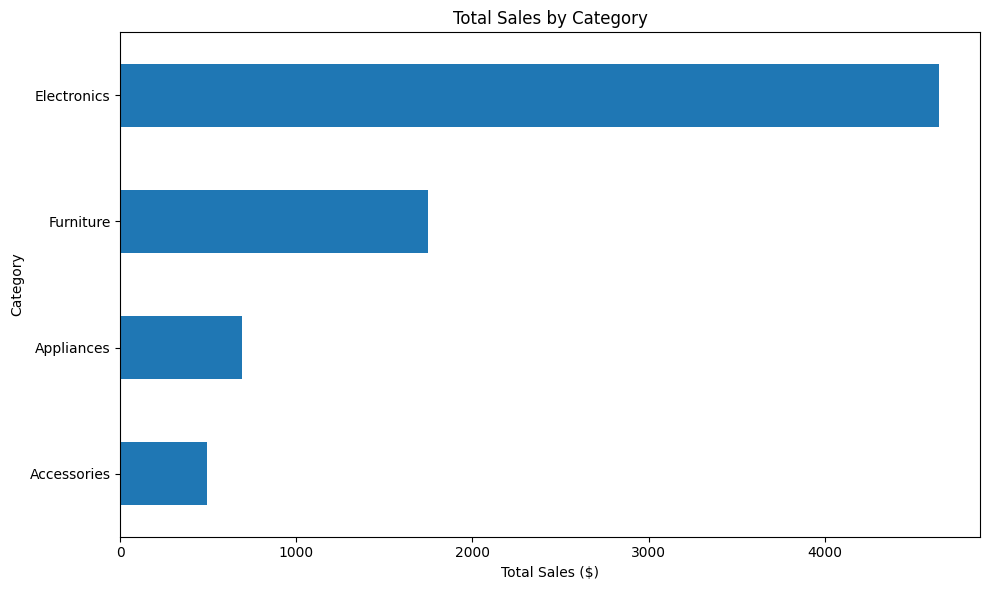

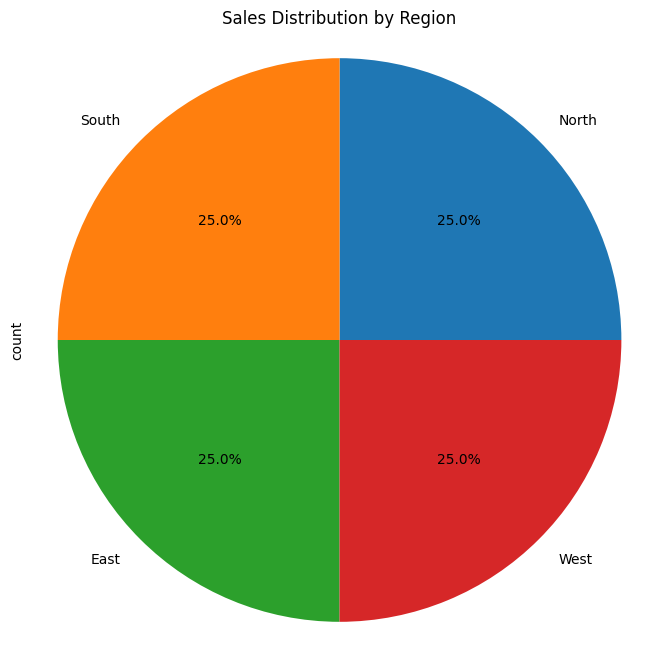


Payment Method Analysis:
                Total_Amount  Customer_ID
Payment_Method                           
Bank Transfer         679.97            2
Credit Card          3559.78            9
Debit Card            989.93            3
PayPal               2349.86            6


In [3]:
# 1. Sales by Category
plt.figure(figsize=(10, 6))
category_sales = df.groupby('Category')['Total_Amount'].sum().sort_values(ascending=True)
category_sales.plot(kind='barh')
plt.title('Total Sales by Category')
plt.xlabel('Total Sales ($)')
plt.tight_layout()
plt.show()

# 2. Regional Distribution
plt.figure(figsize=(8, 8))
df['Region'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Sales Distribution by Region')
plt.axis('equal')
plt.show()

# 3. Payment Method Analysis
payment_analysis = df.groupby('Payment_Method').agg({
    'Total_Amount': 'sum',
    'Customer_ID': 'count'
}).round(2)

print("\nPayment Method Analysis:")
print(payment_analysis)

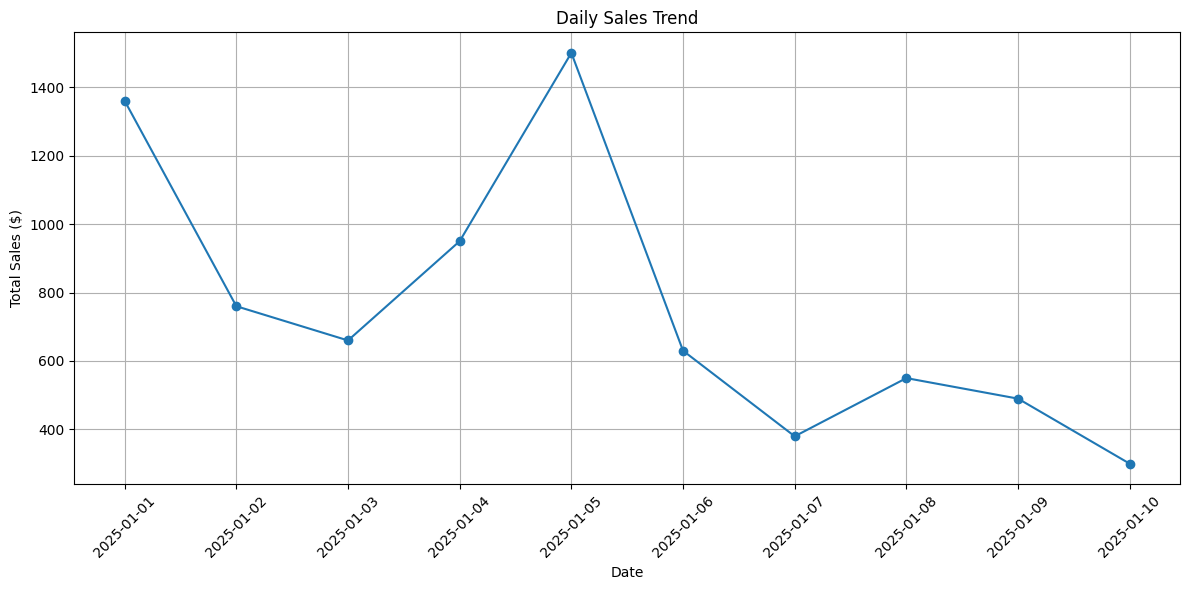


Key Metrics:
Total Revenue: $7,579.54
Average Transaction Value: $378.98
Total Number of Transactions: 20
Total Items Sold: 46
Average Items per Transaction: 2.30

Top 5 Selling Products by Revenue:
               Total_Amount  Quantity
Product                              
Laptop              1299.99         1
Tablet              1199.98         2
Desk Chair           599.97         3
Standing Desk        499.99         1
Office Chair         499.98         2


In [4]:
# Time Series Analysis
daily_sales = df.groupby('Date')['Total_Amount'].sum().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(daily_sales['Date'], daily_sales['Total_Amount'], marker='o')
plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate some key metrics
print("\nKey Metrics:")
print(f"Total Revenue: ${df['Total_Amount'].sum():,.2f}")
print(f"Average Transaction Value: ${df['Total_Amount'].mean():,.2f}")
print(f"Total Number of Transactions: {len(df)}")
print(f"Total Items Sold: {df['Quantity'].sum()}")
print(f"Average Items per Transaction: {df['Quantity'].mean():,.2f}")

# Top selling products
print("\nTop 5 Selling Products by Revenue:")
top_products = df.groupby('Product').agg({
    'Total_Amount': 'sum',
    'Quantity': 'sum'
}).sort_values('Total_Amount', ascending=False).head()
print(top_products)

# Sales Data Analysis

This notebook demonstrates analysis of our sales dataset including:
1. Data Loading and Cleaning
2. Exploratory Data Analysis (EDA)
3. Visualizations
4. Statistical Analysis

## Setup and Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from datetime import datetime

# Set style for better visualizations
plt.style.use('seaborn')
sns.set_palette('deep')
%matplotlib inline

## 1. Data Loading and Cleaning

In [ ]:
# Read the CSV file
df = pd.read_csv('../data/raw/sales_data.csv')

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Display basic information about the dataset
print("Dataset Info:")
df.info()

print("\nFirst few rows:")
df.head()

## 2. Exploratory Data Analysis (EDA)

In [ ]:
# Basic statistics
print("Basic Statistics:")
df.describe()

# Check for missing values
print("\nMissing Values:")
df.isnull().sum()

### 2.1 Category Analysis

In [ ]:
# Sales by Category
category_sales = df.groupby('Category').agg({
    'Total_Amount': 'sum',
    'Quantity': 'sum'
}).round(2)

print("Sales by Category:")
category_sales.sort_values('Total_Amount', ascending=False)

## 3. Visualizations

In [ ]:
# Create a figure with subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Sales by Category
category_sales['Total_Amount'].plot(kind='bar', ax=ax1)
ax1.set_title('Total Sales by Category')
ax1.set_ylabel('Total Sales ($)')
plt.xticks(rotation=45)

# Plot 2: Region Distribution
df['Region'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Sales Distribution by Region')

plt.tight_layout()
plt.show()

### 3.1 Time Series Analysis

In [ ]:
# Daily sales trend
daily_sales = df.groupby('Date')['Total_Amount'].sum().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(daily_sales['Date'], daily_sales['Total_Amount'], marker='o')
plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### 3.2 Payment Method Analysis

In [ ]:
# Payment method analysis using Plotly
payment_analysis = df.groupby('Payment_Method').agg({
    'Total_Amount': 'sum',
    'Customer_ID': 'count'
}).reset_index()

fig = px.bar(payment_analysis, 
             x='Payment_Method', 
             y='Total_Amount',
             title='Sales by Payment Method',
             color='Customer_ID',
             labels={'Total_Amount': 'Total Sales ($)', 
                    'Customer_ID': 'Number of Transactions'})
fig.show()

## 4. Statistical Analysis

In [ ]:
# Correlation analysis
numeric_columns = ['Price', 'Quantity', 'Total_Amount', 'Discount']
correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

### 4.1 Price Distribution Analysis

In [ ]:
# Price distribution by category
plt.figure(figsize=(12, 6))
sns.boxplot(x='Category', y='Price', data=df)
plt.title('Price Distribution by Category')
plt.xticks(rotation=45)
plt.show()

## 5. Key Insights

1. Sales Performance:
   - Analyze the top-performing categories
   - Identify peak sales periods
   - Review regional distribution

2. Payment Preferences:
   - Most popular payment methods
   - Average transaction value by payment type

3. Pricing Strategy:
   - Impact of discounts on sales
   - Price distribution across categories

4. Customer Behavior:
   - Regional preferences
   - Purchase patterns
   - Category preferences